In [3]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [4]:
path1, path2 = 'Sukuna.jpg', 'image2.jpg'
for p in (path1, path2):
    if not os.path.exists(p):
        raise FileNotFoundError(f"{p} does not exist")

img1 = cv2.cvtColor(cv2.imread(path1), cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(cv2.imread(path2), cv2.COLOR_BGR2RGB)

img1 = cv2.resize(img1, (500, 500))
img2 = cv2.resize(img2, (500, 500))

In [5]:
mask = np.zeros((500, 500), dtype=np.uint8)
cv2.circle(mask, (250, 250), 150, 255, thickness=-1)

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(500, 500), dtype=uint8)

In [10]:
fg = cv2.bitwise_and(img1, img1, mask=mask)

mask_inv = cv2.bitwise_not(mask)
bg = cv2.bitwise_and(img2, img2, mask=mask_inv)

combined = cv2.bitwise_or(fg, bg)

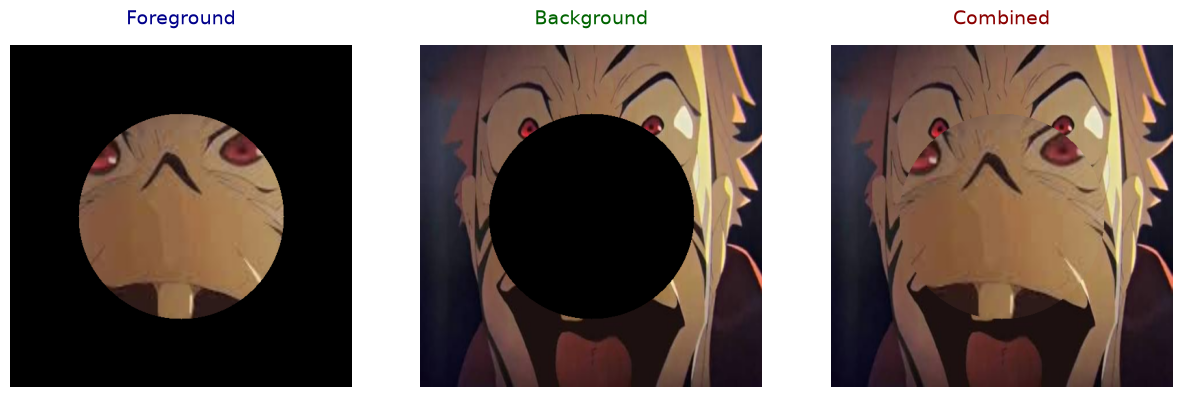

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(fg)
axes[0].axis('off')
axes[0].set_title("Foreground", fontsize=14, color='darkblue', pad=15)

axes[1].imshow(bg)
axes[1].axis('off')
axes[1].set_title("Background", fontsize=14, color='darkgreen', pad=15)

axes[2].imshow(combined)
axes[2].axis('off')
axes[2].set_title("Combined", fontsize=14, color='darkred', pad=15)

plt.show()